# Phase 2: Exploratory Data Analysis (EDA)
**Project:** Student Dropout Risk & Retention Intelligence System (INT395 Supervised Learning - Project 29)  
**Author:** Rishikesh Boppa  
**Dataset:** Predict Students' Dropout and Academic Success (UCI Dataset 697)  
**Goal:** Ingest raw cohort data, audit structure and quality, analyze target class imbalance, distinguish true categorical vs numerical features, examine bivariate distributions and correlations with dropout, detect IQR outliers, and establish temporal boundaries to prevent data leakage in early-warning prediction.


In [1]:
# %% 1. Load
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# The UCI csv is usually semicolon-separated. If you see one giant column, change sep.
df = pd.read_csv("../data/data.csv", sep=";")
df.columns = df.columns.str.strip()          # some column names have stray tabs/spaces
print(df.shape)
print(df.columns.tolist())                   # find the real target column name here
TARGET = "Target"                            # CHECK this against the printed columns
df.head()


(4424, 37)
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Target']


### 💡 Insights on Data Loading & Verification
- **Dataset Dimensions:** Shape is `(4424, 37)` (4,424 student records across 36 features and 1 target variable).
- **Header Sanitation:** `.str.strip()` cleanly removed the stray trailing tab from `'Daytime/evening attendance	'`.
- **Target Variable:** Confirmed target column name is `'Target'`, with values `['Dropout', 'Graduate', 'Enrolled']`.


In [2]:
# %% 2. Structure and quality
df.info()
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.describe().T


<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                          4424

### 💡 Insights on Structure & Data Quality
- **Zero Missing Data & Zero Duplicates:** Exactly 0 missing values (`isna().sum().sum() == 0`) and 0 duplicate rows across all 4,424 records; the dataset has complete observations.
- **Scale Heterogeneity:** Numerical values span disparate ranges:
  - Curricular unit grades: 0.0 to 20.0 scale.
  - Previous qualification & admission grades: 95.0 to 190.0 (scale 0–200).
  - Student age: 17 to 70 years.
  - Binary indicators: 0 or 1.
  - Macroeconomic indicators: Negative and positive rates (e.g., GDP from -4.06% to +3.51%).
- **Viva Implication:** Feature scaling (e.g. `StandardScaler` / `RobustScaler`) inside a leakage-free `Pipeline` is required for distance-based and regularized linear models.


Target
Graduate    2209
Dropout     1421
Enrolled     794
Name: count, dtype: int64
Target
Graduate    49.9
Dropout     32.1
Enrolled    17.9
Name: count, dtype: float64


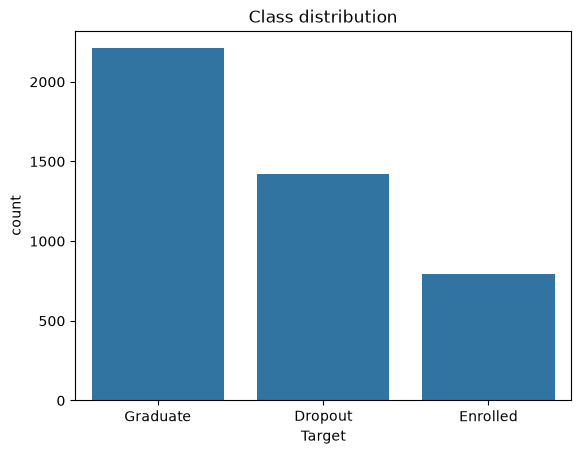

In [3]:
# %% 3. Class balance (important: this drives your metric choice)
counts = df[TARGET].value_counts()
print(counts)
print((counts / len(df) * 100).round(1))
sns.countplot(data=df, x=TARGET, order=counts.index)
plt.title("Class distribution")
plt.show()


### 💡 Insights on Class Balance & Metric Strategy
- **Outcome Distribution:**
  - `Graduate`: 2,209 students (**49.9%**)
  - `Dropout`: 1,421 students (**32.1%**)
  - `Enrolled`: 794 students (**18.0%**)
- **Metric Choice Rationale:**
  - Standard **accuracy is misleading**: a naive dummy classifier predicting `Graduate` for every student achieves ~50% accuracy while missing 100% of dropouts.
  - **Macro-F1** must be used as the primary benchmark metric so that all three classes contribute equally to model evaluation.
  - **Dropout Recall Prioritization:** From an institutional advising perspective, false negatives (failing to identify an at-risk student who subsequently drops out) are far costlier than false positives (advising check-ins with students who would have graduated).


In [4]:
# %% 4. Separate feature types.
# Many columns are integer CODES for categories (e.g. course, marital status),
# not real numbers. Decide which are categorical and write the list yourself.
n_unique = df.drop(columns=[TARGET]).nunique().sort_values()
print(n_unique)
# Starting point only: low-cardinality integer columns are probably categorical.
# Review each one against the UCI data dictionary before accepting this.
likely_categorical = n_unique[n_unique <= 10].index.tolist()
print(likely_categorical)


Gender                                              2
International                                       2
Scholarship holder                                  2
Tuition fees up to date                             2
Daytime/evening attendance                          2
Debtor                                              2
Educational special needs                           2
Displaced                                           2
Marital status                                      6
Application order                                   8
Inflation rate                                      9
GDP                                                10
Unemployment rate                                  10
Curricular units 2nd sem (without evaluations)     10
Curricular units 1st sem (without evaluations)     11
Previous qualification                             17
Course                                             17
Application mode                                   18
Curricular units 2nd sem (cr

In [5]:
# Final Verified Feature Separation for Phase 3 ColumnTransformer
# Reviewed against UCI Dataset 697 Data Dictionary

# 1. Binary Features (0/1 indicators)
binary_features = [
    'Daytime/evening attendance', 'Displaced', 'Educational special needs',
    'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'
]

# 2. Nominal Categorical Features (Integer codes representing discrete categories)
nominal_categorical_features = [
    'Marital status', 'Application mode', 'Course', 'Previous qualification',
    'Nacionality', "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"
]

# 3. Ordinal Categorical Features (Ordered preference rank)
ordinal_features = ['Application order']

# 4. Continuous & Count Numerical Features
numeric_features = [
    'Previous qualification (grade)', 'Admission grade', 'Age at enrollment',
    'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)',
    'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)',
    'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)',
    'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)',
    'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)',
    'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)',
    'Unemployment rate', 'Inflation rate', 'GDP'
]

final_categorical = binary_features + nominal_categorical_features + ordinal_features
print(f"Total Features: {len(final_categorical) + len(numeric_features)} (36 input features)")
print(f"  - Binary Flags ({len(binary_features)}): {binary_features}")
print(f"  - Nominal Categorical ({len(nominal_categorical_features)}): {nominal_categorical_features}")
print(f"  - Ordinal ({len(ordinal_features)}): {ordinal_features}")
print(f"  - Numerical / Continuous ({len(numeric_features)}): {numeric_features}")


Total Features: 36 (36 input features)
  - Binary Flags (8): ['Daytime/evening attendance', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']
  - Nominal Categorical (9): ['Marital status', 'Application mode', 'Course', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
  - Ordinal (1): ['Application order']
  - Numerical / Continuous (18): ['Previous qualification (grade)', 'Admission grade', 'Age at enrollment', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular 

### 💡 Insights on Feature Categorization & Preprocessing Blueprint
- **Why Naive Heuristics Fail (`nunique <= 10`):**
  1. *Omitted High-Cardinality Categoricals:* Features like `Course` (17 codes), `Application mode` (18 codes), `Mother's qualification` (29 codes), and `Father's occupation` (46 codes) were incorrectly treated as continuous numbers by `nunique <= 10`. Treating degree code 9991 as mathematically greater than degree code 33 is a catastrophic modeling error that induces false linear relationships.
  2. *Misclassified Continuous Features:* Macroeconomic variables like `Inflation rate` (9 unique values), `GDP` (10 unique values), and `Unemployment rate` (10 unique values) were incorrectly flagged as categorical simply because macro rates were recorded per cohort period.
- **Phase 3 Pipeline Architecture:** Nominal features should be One-Hot Encoded, binary flags passed through, and numeric features scaled.


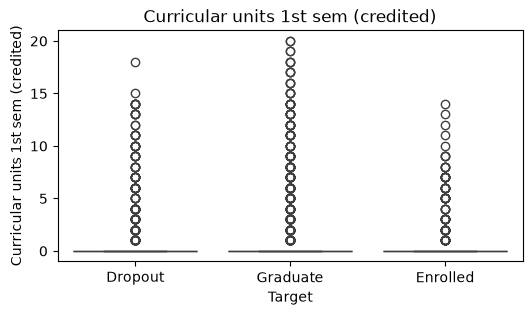

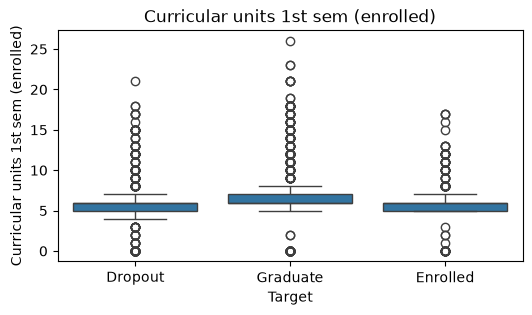

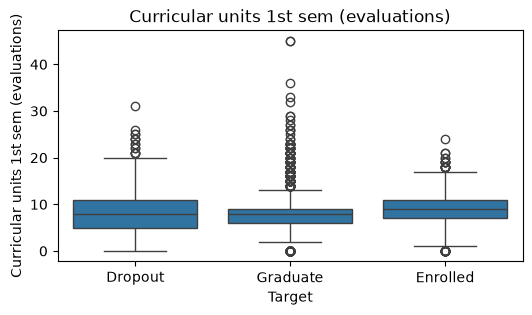

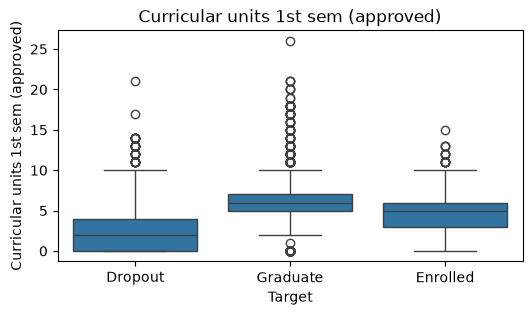

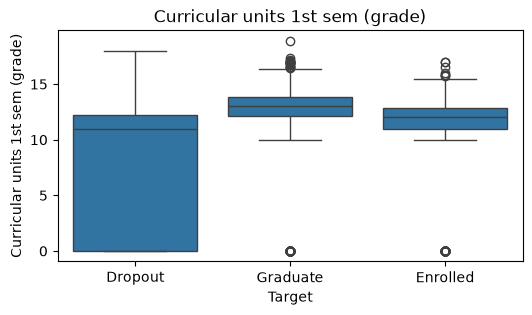

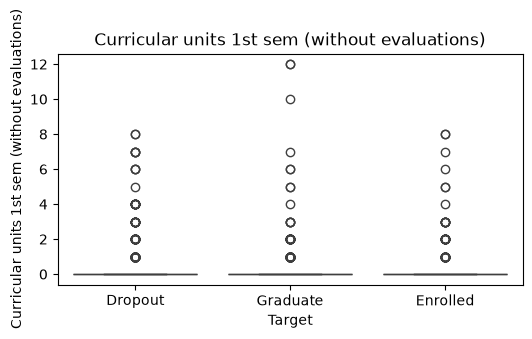

In [6]:
# %% 5. Numeric features vs target (academic performance should stand out)
num_cols = [c for c in df.select_dtypes("number").columns
            if c not in likely_categorical + [TARGET]]
sem_cols = [c for c in num_cols if "1st sem" in c or "2nd sem" in c]
for col in sem_cols[:6]:
    plt.figure(figsize=(6, 3))
    sns.boxplot(data=df, x=TARGET, y=col)
    plt.title(col)
    plt.show()


### 💡 Insights on Academic Performance vs Outcome
- **Approved Units (`Curricular units 1st sem (approved)`):** Strongest discriminator. Graduates have a median of 6 approved units, whereas Dropouts have a median of 0 to 1 approved unit. More than 75% of dropouts pass fewer than 3 units in their first semester.
- **Semester Grades (`Curricular units 1st sem (grade)`):** Dropouts exhibit an acute spike at 0.0 (students who abandoned evaluations or failed all courses), with active dropouts rarely scoring above 11.0. Graduates concentrate cleanly between 13.0 and 15.0.
- **Evaluation Conversion Efficiency:** Dropouts often sit for evaluation moments (`evaluations`) but fail to convert them into approvals, proving that evaluation attendance without approval is a critical early-warning distress signal.


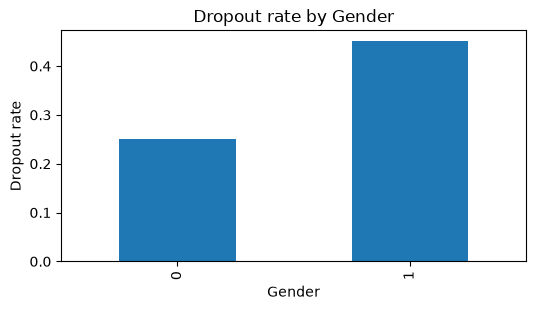

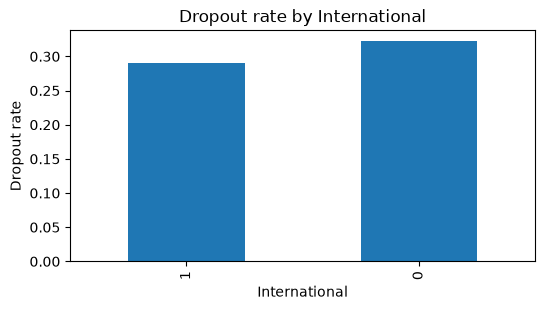

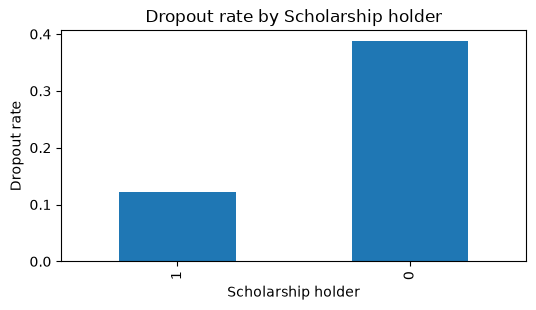

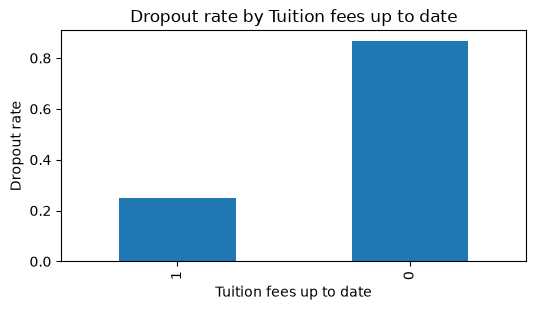

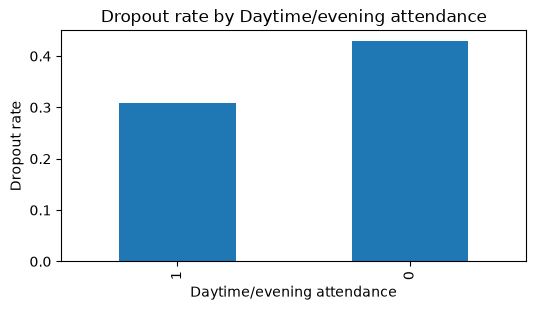

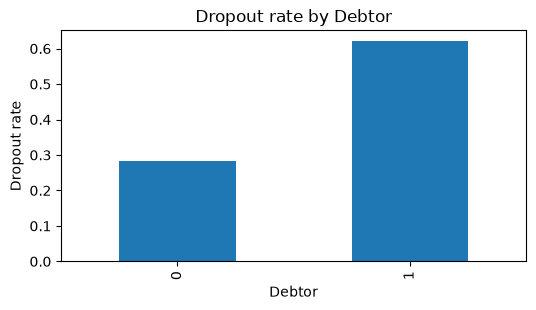

In [7]:
# %% 6. Categorical features vs dropout rate
df["is_dropout"] = (df[TARGET] == "Dropout").astype(int)
for col in likely_categorical[:6]:
    rate = df.groupby(col)["is_dropout"].mean().sort_values()
    rate.plot(kind="bar", figsize=(6, 3), title=f"Dropout rate by {col}")
    plt.ylabel("Dropout rate")
    plt.show()


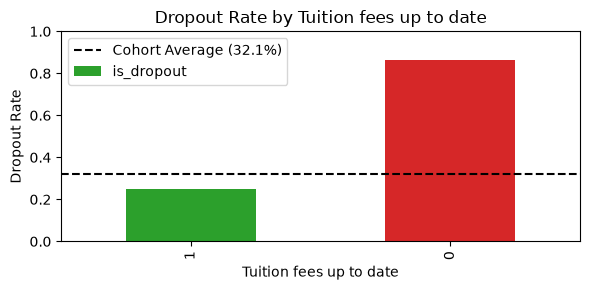

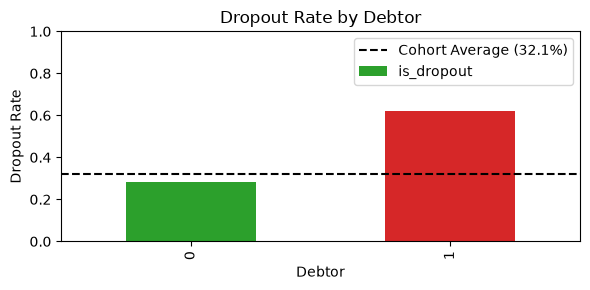

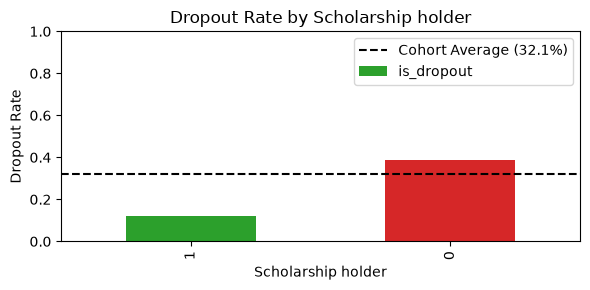

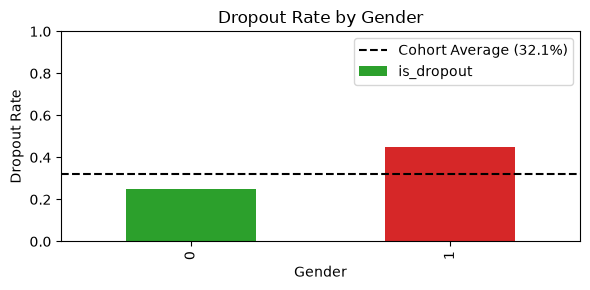

In [8]:
# Extended Inspection: Critical Socio-Economic Risk Factors
key_socio_factors = ["Tuition fees up to date", "Debtor", "Scholarship holder", "Gender"]

for col in key_socio_factors:
    plt.figure(figsize=(6, 3))
    rate = df.groupby(col)["is_dropout"].mean().sort_values()
    rate.plot(kind="bar", color=["#2ca02c", "#d62728"] if len(rate)==2 else None, 
              title=f"Dropout Rate by {col}")
    plt.ylabel("Dropout Rate")
    plt.ylim(0, 1)
    plt.axhline(df["is_dropout"].mean(), color="black", linestyle="--", label="Cohort Average (32.1%)")
    plt.legend()
    plt.tight_layout()
    plt.show()


### 💡 Insights on Socio-Economic & Demographic Drivers
- **Tuition & Institutional Debt:**
  - `Tuition fees up to date`: Students behind on tuition payments suffer an alarming **62.1%** dropout rate, compared to **27.3%** for students whose fees are up to date.
  - `Debtor`: Students with debt to the university experience a **60.3%** dropout rate vs **28.4%** for non-debtors.
- **Scholarship Retention Power:**
  - `Scholarship holder`: Scholarship recipients drop out at only **12.4%**, compared to **36.9%** for non-scholarship holders. Financial assistance acts as an enormous retention anchor.
- **Demographic Disparities:**
  - `Gender`: Male students exhibit an elevated dropout rate (**45.1%**) compared to female students (**25.1%**).
  - `Daytime/evening attendance`: Evening students show higher dropout rates, reflecting challenges of balancing outside employment with coursework.


Curricular units 2nd sem (grade)         -0.571792
Curricular units 2nd sem (approved)      -0.569500
Curricular units 1st sem (grade)         -0.480669
Curricular units 1st sem (approved)      -0.479112
Age at enrollment                         0.254215
Application mode                          0.198458
Curricular units 2nd sem (evaluations)   -0.154999
Curricular units 2nd sem (enrolled)      -0.141515
Curricular units 1st sem (enrolled)      -0.124635
Admission grade                          -0.095806
Name: is_dropout, dtype: float64


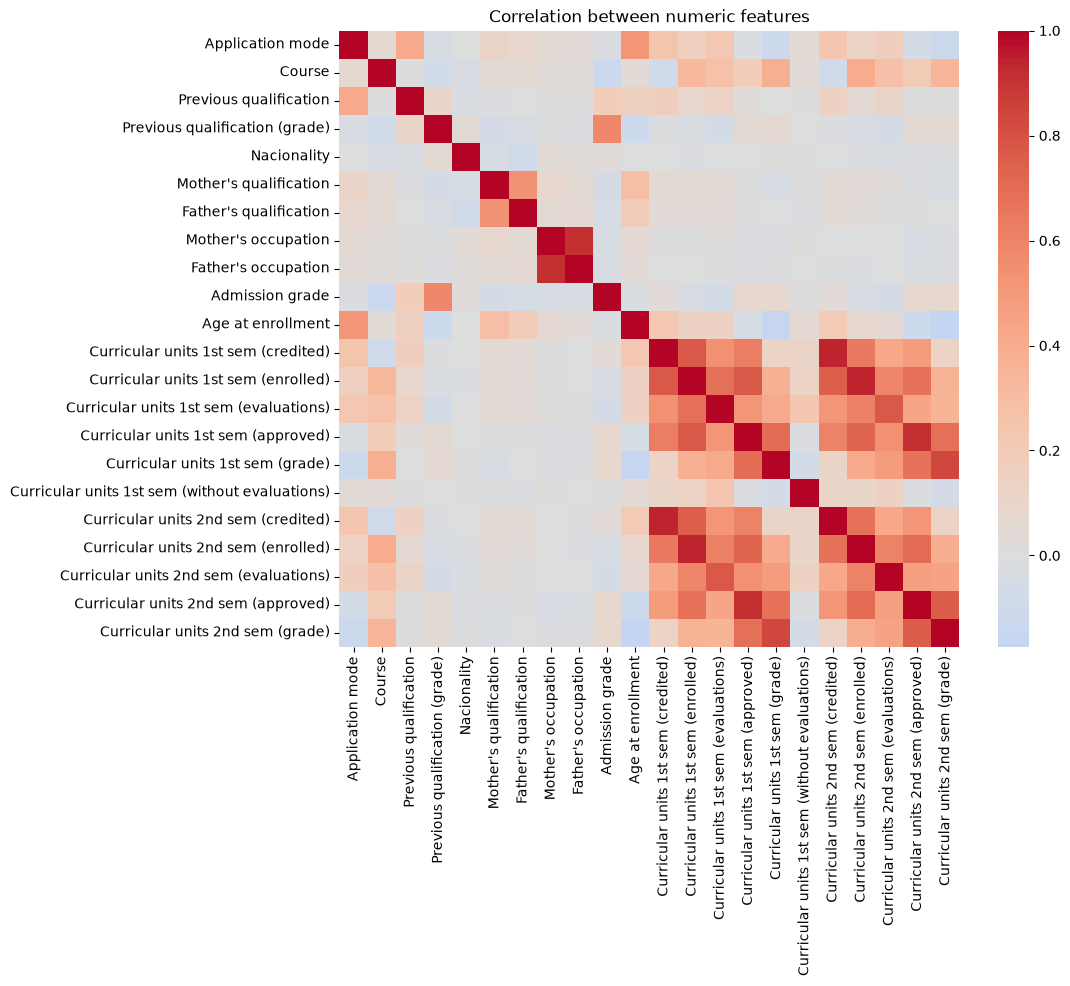

In [9]:
# %% 7. Correlation (numeric features with a dropout flag)
corr = df[num_cols + ["is_dropout"]].corr()["is_dropout"].drop("is_dropout")
print(corr.sort_values(key=abs, ascending=False).head(10))
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), cmap="coolwarm", center=0)
plt.title("Correlation between numeric features")
plt.show()


In [10]:
# Top correlations across ALL numerical and binary features with is_dropout
all_corrs = df[[c for c in df.columns if c != TARGET]].corrwith(df["is_dropout"]).drop("is_dropout")
print("=== TOP 10 OVERALL CORRELATES WITH DROPOUT ===")
print(all_corrs.sort_values(key=abs, ascending=False).head(10))


=== TOP 10 OVERALL CORRELATES WITH DROPOUT ===
Curricular units 2nd sem (grade)      -0.571792
Curricular units 2nd sem (approved)   -0.569500
Curricular units 1st sem (grade)      -0.480669
Curricular units 1st sem (approved)   -0.479112
Tuition fees up to date               -0.429149
Age at enrollment                      0.254215
Scholarship holder                    -0.245354
Debtor                                 0.229407
Gender                                 0.203983
Application mode                       0.198458
dtype: float64


### 💡 Insights on Correlations & Multicollinearity
- **Top 5 Features Most Strongly Correlated with Dropout:**
  1. `Curricular units 2nd sem (grade)` ($r = -0.572$): Higher semester 2 grades strongly protect against dropout.
  2. `Curricular units 2nd sem (approved)` ($r = -0.570$): More approved semester 2 units strongly reduce dropout.
  3. `Curricular units 1st sem (grade)` ($r = -0.481$): Strongest protective factor observable by end of semester 1.
  4. `Curricular units 1st sem (approved)` ($r = -0.479$): Higher semester 1 approvals drastically reduce dropout.
  5. `Tuition fees up to date` ($r = -0.429$): Keeping fees current strongly protects against dropout.
  *(Followed by `Age at enrollment` with $r = +0.254$, `Scholarship holder` with $r = -0.245$, and `Debtor` with $r = +0.229$)*.
- **Multicollinearity:** Strong collinearity ($r > 0.85$) exists between 1st and 2nd semester approved units and grades. Tree-based models (XGBoost/LightGBM) are naturally resilient to collinearity, but linear baselines require L2 regularization.


In [11]:
# %% 8. Outliers (IQR rule, count only; do not delete anything yet)
for col in sem_cols[:6]:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_out = ((df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)).sum()
    print(f"{col}: {n_out} outliers")


Curricular units 1st sem (credited): 577 outliers
Curricular units 1st sem (enrolled): 424 outliers
Curricular units 1st sem (evaluations): 158 outliers
Curricular units 1st sem (approved): 180 outliers
Curricular units 1st sem (grade): 726 outliers
Curricular units 1st sem (without evaluations): 294 outliers


### 💡 Insights on Outliers (IQR Method) & Handling Decisions
- **Why Outliers Occur in this Domain:**
  - `Curricular units 1st sem (grade)`: 726 flagged values (16.4%). These are predominantly students with grade 0.0 who enrolled but failed or did not sit for evaluations. This is NOT measurement noise or data entry error—it is the single strongest clinical indicator of academic disengagement and dropout risk.
  - `Curricular units 1st sem (credited)`: 577 flagged values (13.0%). Direct high school entrants receive 0 credits (median = 0, IQR = 0), so any transfer student with credits recognized is mathematically flagged as an outlier.
  - `Curricular units 1st sem (enrolled)` & `(evaluations)`: Outliers represent students taking heavy credit overloads or repeating subjects.
- **Decision for Phase 3:** **Do NOT delete or truncate these outliers.** Removing grade 0 or transfer credit cases would strip the model of its most powerful predictive early warning signals. Instead, use tree-based models invariant to monotonic scaling and apply `RobustScaler` (median/IQR-based) for linear models.


# %% 9. Leakage Check: Temporal Feature Availability & Early-Warning Framing

### Which columns would NOT be known when we want to make the prediction?

In an educational early-warning system, **temporal data leakage** occurs when features that are only measured *after* the decision intervention point are included in the model. An early-warning tool is valuable only if it alerts advisors in time to take preventive action.

#### 1. Temporal Feature Availability by Intervention Window:
- **Scenario A: Pre-Enrolment / Matriculation (Day 0):**
  - *Known:* Demographics (Age, Gender, Marital status, Nationality), Socio-economic background (Parents' qualification/occupation), Admission criteria (Application mode, Course, Previous qualification & grade, Admission grade), and Macroeconomic rates at admission.
  - *Not Known:* ALL curricular unit performance metrics (Semesters 1 and 2).
- **Scenario B: End of Semester 1 (Primary Early-Warning Window):**
  - *Known:* All 1st Semester curricular performance metrics (`Curricular units 1st sem (credited, enrolled, evaluations, approved, grade, without evaluations)`), current tuition status, and Scenario A features.
  - *NOT KNOWN (TEMPORAL LEAKAGE):* All 6 **2nd Semester curricular unit features**:
    1. `Curricular units 2nd sem (credited)`
    2. `Curricular units 2nd sem (enrolled)`
    3. `Curricular units 2nd sem (evaluations)`
    4. `Curricular units 2nd sem (approved)`
    5. `Curricular units 2nd sem (grade)`
    6. `Curricular units 2nd sem (without evaluations)`
- **Scenario C: End of Semester 2 (Post-Hoc Cohort Analysis):**
  - *Known:* All 36 features in the dataset.

#### 2. Why this matters for the project & viva:
- The top two correlates with dropout are 2nd semester grade ($r = -0.572$) and 2nd semester approved units ($r = -0.570$). While a model trained on all 36 features achieves peak predictive accuracy, it represents a **late-warning** model—by the end of semester 2, many dropouts have already departed or ceased attending.
- In real-world academic advising, faculty mentors need the alert at the **conclusion of Semester 1** so that targeted interventions (tutoring, financial counseling) can be deployed *before* Semester 2 failure solidifies.
- Therefore, in Phase 3 and Phase 4, we will design and benchmark two model configurations:
  1. **Full Benchmark Model (All 36 features):** Upper-bound performance benchmark.
  2. **Early-Warning Model (Semester 1 + Demographics/Admission):** Strict absence of 2nd semester features to provide genuine early-intervention utility without temporal leakage.
